In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.postproc import *
from functions.ensembles import *
from functions.repeated_cv import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data.csv")

diagnosis_variables = []

with open("../../data/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Stratification settings (toggle this flag)
n_splits = 5
use_time_strata = False  # Set to False to use outcome-only stratification
max_time_bins = 3

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

if use_time_strata:
    # Outcome-Length stratification: time bins only for recurrence cases
    for n_bins in range(max_time_bins, 1, -1):
        try:
            # Build quantile bins using only recurrence cases
            recurrence_time_bins = pd.qcut(
                time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
            )

            # Non-recurrence rows share one label; recurrence rows get time-bin labels
            candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
            candidate_labels.loc[recurrence_mask] = (
                '1_' + recurrence_time_bins.astype(int).astype(str)
            ).values

            # Every stratum must have at least n_splits samples for stable balancing
            if candidate_labels.value_counts().min() >= n_splits:
                strata_labels = candidate_labels
                chosen_bins = int(recurrence_time_bins.nunique())
                break
        except ValueError:
            continue

if strata_labels is None:
    # Explicit switch OR sparse recurrence-time bins -> outcome-only stratification
    strata_labels = event_col.astype(str)
    if use_time_strata:
        print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
    else:
        print('Using outcome-only stratification (time-based stratification disabled).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=302
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[0]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

Using outcome-only stratification (time-based stratification disabled).
Manual grouped fold balancing summary:
 fold  target_events  assigned_events  target_samples  assigned_samples  valid_event_rate  target_event_strata_1  assigned_event_strata_1
    1              6                6             646               646          0.009288                      6                        6
    2              6                6             646               646          0.009288                      6                        6
    3              5                5             646               646          0.007740                      5                        5
    4              5                5             645               645          0.007752                      5                        5
    5              5                5             645               645          0.007752                      5                        5
Train size: 2582, Test size: 646


## Grid search

Mirrors `cox.ipynb` / `cox_new_new.csv` so the two are directly comparable:

| | setting |
|---|---|
| data | `../../data/data.csv` (same cohort as the Cox run, one-hot without `drop_first`) |
| outer split | `build_manual_stratified_group_folds(..., n_splits=5, random_state=12)`, fold index 3 |
| inner CV | `generate_cv_splits(n_splits=4, n_repeats=5, base_random_state=42)` |
| selection metric | Harrell's C-index |

Every grid-search function in `functions/repeated_cv.py` shares `generate_cv_splits`, so
at the same `n_splits` / `n_repeats` / `base_random_state` these 20 train/validation
folds are **identical** to the ones the Cox run scored on — the C-indices compare fold
for fold.

Only 22 events sit in the training split (~17 per inner training fold, ~5 per validation
fold), which is why the grids below go after regularisation strength rather than model
capacity and stay deliberately small: every extra grid point is one more chance for the
CV winner to be picked by noise.

In [20]:
param_grid = {
    # Stage 1 result: n_estimators plateaued by 300 (0.8419 @300, 0.8407 @500,
    # 0.8429 @1000 -- all within the +-0.065 fold noise), so it is NOT the
    # dominant knob for this dataset. Fixed at 300 to keep stage 2 cheap while
    # still on the plateau.
    'n_estimators': [300],
    # Stage 2: capacity/regularisation axes. With ~17 events per inner training
    # fold, deep fully-grown trees isolate single events, so shallow depths and
    # large leaves are the region worth searching.
    'max_depth': [None, 5, 10],
    'min_samples_split': [6],
    'min_samples_leaf': [3, 8, 15, 25],
    # 'sqrt' -> ~6 of the ~35 features per split (strongest decorrelation),
    # None -> all features (weakest).
    'max_features': ['sqrt', 0.5, None],
}

# C-index only, to match cox_new_new.csv exactly. 'c-index-ipcw' and
# 'cumulative-dynamic-auc' can be appended here: they are computed from the same
# risk scores, cost almost nothing, and do not change the c-index column.
metrics = ['c-index']

n_combinations = 1
for values in param_grid.values():
    n_combinations *= len(values)
print(f'{n_combinations} combinations x 20 fits = {n_combinations * 20} model fits')

36 combinations x 20 fits = 720 model fits


In [21]:
# --- Optional, NOT part of the CV comparison ------------------------------
# Bootstrap optimism correction, the counterpart of cox.ipynb's
# subsampling_bootstrap_optimism_grid_search. Implemented as its own section further
# down ("Bootstrap optimism correction", right after the final model check below), run
# at the single winning configuration rather than over a grid -- 500 bootstraps over the
# full grid tested above would take weeks.


In [15]:
# Plain RandomSurvivalForest on the full training fold -- the like-for-like
# counterpart to the Coxnet run (n_controls='Full', i.e. no case-control
# subsampling). The previous version of this cell called
# cc_rsf_repeated_grid_search, which fits a *different* estimator
# (CaseControlRandomSurvivalForest, per-tree case-control subsampling) and so
# was not comparable with cox_new_new.csv.
#
# Stage 2: 36 combinations x 20 fits, n_estimators fixed at 300. Based on the
# stage 1 timing (~0.3-0.4min per n_estimators=300 config), expect roughly
# 10-15 min.
results_df, summary_df, best_params = ensemble_repeated_grid_search(
    RandomSurvivalForest, x_train, y_train, param_grid, metrics,
    model_name='RSF Model',
    scale_data=False,               # trees are scale invariant
    continuous_features=None,
    random_state=42,                # reproducible forests
    n_jobs=-1,
    n_controls_per_case='Full',     # no subsampling, same as the cox run's n_controls='Full'
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


RSF MODEL REPEATED GRID SEARCH
Model: RandomSurvivalForest
Scaling: No
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - n_estimators: [300]
  - max_depth: [None, 5, 10]
  - min_samples_split: [6]
  - min_samples_leaf: [3, 8, 15, 25]
  - max_features: ['sqrt', 0.5, None]
Total hyperparameter combinations: 36
Folds per repetition: 4
Repetitions: 5
Total evaluations: 720

[1/36] Testing params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 3, 'max_features': 'sqrt'}, n_controls_per_case=Full (no subsampling)
  c-index: 0.8334 ± 0.0743
[2/36] Testing params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 3, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  Elapsed: 0.9min, Est. remaining: 32.6min
  c-index: 0.8249 ± 0.0783
[3/36] Testing params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 3, 'max_features': None}, n_control

In [16]:
# Drop configurations where any fold failed, then match cox_new_new.csv's
# layout: a CV column (coefficient of variation = std / mean, i.e. fold-to-fold
# instability per unit of performance) and best-first ordering.
rsf_clean = clean_cox_data(summary_df)

# groupby turns None hyperparameters into NaN, which is indistinguishable from a
# genuinely missing value once written to CSV. Spell them out instead:
# max_depth=None means unlimited depth, max_features=None means all features.
param_cols = [c for c in rsf_clean.columns
              if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols:
    if rsf_clean[col].isna().any():
        rsf_clean[col] = rsf_clean[col].astype(object).where(rsf_clean[col].notna(), 'None')

rsf_clean['CV'] = rsf_clean['c-index_std'] / rsf_clean['c-index_mean']
rsf_clean = rsf_clean.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_clean.to_csv('rsf_new.csv', index=False)

display_cols = [c for c in rsf_clean.columns if '_repeat_' not in c]
print(rsf_clean[display_cols].head(15).to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (36 -> 36)
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
          300      10.0                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          300      None                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          300      None                  6                15         sqrt                Full                 None             None          None      0.848578     0.063242 0.074527
          300       5.0                  6                 3         sqrt                Full                 None             None          None      0.

## Grid search, extension: zoom into the winning region

`rsf_new.csv` (36 configurations) shows a few clear patterns:

- `max_depth` barely matters: every `(min_samples_leaf, max_features)` pair
  scores identically whether `max_depth` is `10` or `None` -- trees never
  actually grow past depth 10 on this data, so those two values are redundant.
  `max_depth=5` is the only depth setting that changes the result, and it cuts
  both ways: it drags the best `max_features=0.5` configuration down (0.8514
  unlimited vs 0.8474 at depth=5) but lifts the shallow-leaf ones
  (`min_samples_leaf=3, max_features=sqrt`: 0.8486 at depth=5 vs 0.8334-0.8345
  unlimited -- the second-best result in the whole table). So depth stays in
  the grid, just deduplicated to `[5, None]`.
- `max_features=None` (all ~35 features per split, weakest decorrelation) is
  the worst setting at every `min_samples_leaf` tested, consistently at or
  near the bottom of the ranking (0.8209-0.8476). Dropped.
- `min_samples_leaf=8` is a consistent local minimum -- worse than both its
  neighbours (`3` and `15`) at every `max_features` value, a pattern that
  repeats across all three feature settings rather than showing up once, so it
  reads as real rather than fold noise. `min_samples_leaf=15` is the single
  best value (wins outright with `max_features=0.5`) and `25` is a close
  second-best; `3` is weak on its own but strong paired with `max_depth=5`.

This extension drops `max_features=None` and the redundant `max_depth=10`, and
replaces the single leaf values tested so far with a finer sweep from 5 to 30
that brackets the winner (15) and probes past the second-best point (25) to
see whether performance is still climbing there.

Same folds/settings as `rsf_new.csv`, so the two concatenate directly into one
ranked table.

In [22]:
# Zoomed grid: max_depth deduplicated to [5, None] (10 and None tied exactly
# in rsf_new.csv -- trees never reach depth 10 on this data), max_features=None
# dropped (worst at every leaf size), min_samples_leaf swept finer around the
# winning region (15) and extended past the second-best point (25).
param_grid_ext = {
    'n_estimators': [300],
    'max_depth': [5, None],
    'min_samples_split': [6],
    'min_samples_leaf': [5, 10, 15, 20, 25, 30],
    'max_features': ['sqrt', 0.5],
}

metrics = ['c-index']

n_combinations_ext = 1
for values in param_grid_ext.values():
    n_combinations_ext *= len(values)
print(f'{n_combinations_ext} combinations x 20 fits = {n_combinations_ext * 20} model fits')

24 combinations x 20 fits = 480 model fits


In [23]:
# Same folds, scaling and settings as the stage 2 grid above.
#
# 24 combinations x 20 fits, same per-fit cost as stage 2 (n_estimators still
# 300) -> expect roughly 7-10 min.
results_df_ext, summary_df_ext, best_params_ext = ensemble_repeated_grid_search(
    RandomSurvivalForest, x_train, y_train, param_grid_ext, metrics,
    model_name='RSF Model (leaf/features extension)',
    scale_data=False,               # trees are scale invariant
    continuous_features=None,
    random_state=42,                # reproducible forests
    n_jobs=-1,
    n_controls_per_case='Full',     # no subsampling, same as the cox run's n_controls='Full'
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


RSF MODEL (LEAF/FEATURES EXTENSION) REPEATED GRID SEARCH
Model: RandomSurvivalForest
Scaling: No
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - n_estimators: [300]
  - max_depth: [5, None]
  - min_samples_split: [6]
  - min_samples_leaf: [5, 10, 15, 20, 25, 30]
  - max_features: ['sqrt', 0.5]
Total hyperparameter combinations: 24
Folds per repetition: 4
Repetitions: 5
Total evaluations: 480

[1/24] Testing params: {'n_estimators': 300, 'max_depth': 5, 'min_samples_split': 6, 'min_samples_leaf': 5, 'max_features': 'sqrt'}, n_controls_per_case=Full (no subsampling)
  c-index: 0.8391 ± 0.0668
[2/24] Testing params: {'n_estimators': 300, 'max_depth': 5, 'min_samples_split': 6, 'min_samples_leaf': 5, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  Elapsed: 1.2min, Est. remaining: 27.0min
  c-index: 0.8365 ± 0.0768
[3/24] Testing params: {'n_estimators': 300, 'max_depth': 5, 'min_samples_split': 6, 'min_samples_leaf': 10, 'max_features':

In [24]:
# Same cleanup as the stage 2 grid, saved separately as 'rsf_ext.csv'
# (identical schema to 'rsf_new.csv', so the two concatenate directly).
rsf_clean_ext = clean_cox_data(summary_df_ext)

param_cols_ext = [c for c in rsf_clean_ext.columns
                  if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_ext:
    if rsf_clean_ext[col].isna().any():
        rsf_clean_ext[col] = rsf_clean_ext[col].astype(object).where(rsf_clean_ext[col].notna(), 'None')

rsf_clean_ext['CV'] = rsf_clean_ext['c-index_std'] / rsf_clean_ext['c-index_mean']
rsf_clean_ext = rsf_clean_ext.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_clean_ext.to_csv('rsf_ext.csv', index=False)

display_cols_ext = [c for c in rsf_clean_ext.columns if '_repeat_' not in c]
print(rsf_clean_ext[display_cols_ext].head(15).to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (24 -> 24)
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
          300      None                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          300      None                  6                20         sqrt                Full                 None             None          None      0.850555     0.063334 0.074462
          300      None                  6                30          0.5                Full                 None             None          None      0.849925     0.071839 0.084523
          300       5.0                  6                30          0.5                Full                 None             None          None      0.

In [ ]:
# keep_default_na=False: pandas' default NA list includes the literal string
# "None", which is exactly what the cleanup cells write for max_depth=None /
# max_features=None. Without this flag, reloading the CSV silently turns
# "unlimited depth" into a missing value and splits one config into two rows
# (visible in the previous version of rsf_combined.csv).
rsf_clean = pd.read_csv('rsf_new.csv', keep_default_na=False)

## Grid search, stage 3: does n_estimators still plateau at the actual best configs?

`rsf_combined.csv` (60 rows across both grids) confirms `min_samples_leaf=15`
+ `max_features=0.5` + any depth as the outright winner (0.8514), with
`min_samples_leaf=20` + `max_features=sqrt` close behind (0.8506) and
`min_samples_leaf=3` + `max_depth=5` + `max_features=sqrt` a distinct third
mode (0.8486). That third one looks like a real effect, not noise: every
other `max_depth` at `min_samples_leaf=3` scores 0.017-0.019 lower
(0.830-0.835) -- depth genuinely constrains overfitting when leaves are this
small, unlike `min_samples_leaf>=15`, where the leaf-size floor already caps
tree growth and depth makes no difference (see the extension markdown above).

Stage 1's n_estimators plateau ("300 is enough") was measured at
`max_depth=5, min_samples_leaf=8, max_features=sqrt` -- and `min_samples_leaf=8`
has since turned out to be one of the *worst* leaf sizes tested, a consistent
local minimum. That plateau was found at a mediocre configuration, so before
settling on a final model it's worth checking n_estimators directly at the
configurations that actually won, rather than assuming the earlier result
transfers.

This stage re-tests `n_estimators in [100, 500, 1000]` (300 is already covered
by the two grids above) at the three configurations described above, one grid
search call per configuration so no cross-product combinations are wasted on
pairings nobody is asking about.

In [30]:
# The three configurations worth re-checking against n_estimators: the
# outright winner, its closest competitor, and the distinct shallow/aggressive
# mode (see markdown above for why each one is here).
top_configs = [
    {'label': 'leaf=15, features=0.5, depth=None (best)',
     'max_depth': None, 'min_samples_leaf': 15, 'max_features': 0.5},
    {'label': 'leaf=20, features=sqrt, depth=None (2nd)',
     'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'sqrt'},
    {'label': 'leaf=3, features=sqrt, depth=5 (shallow/aggressive)',
     'max_depth': 5, 'min_samples_leaf': 3, 'max_features': 'sqrt'},
]

n_estimators_to_test = [100, 500, 1000]  # 300 already covered above

n_combinations_stage3 = len(top_configs) * len(n_estimators_to_test)
print(f'{n_combinations_stage3} combinations x 20 fits = {n_combinations_stage3 * 20} model fits')

9 combinations x 20 fits = 180 model fits


In [31]:
# One ensemble_repeated_grid_search call per configuration -- same folds and
# settings as the grids above, only n_estimators varies within each call.
#
# 9 combinations x 20 fits total. Expect roughly 3-5 min.
stage3_frames = []
for cfg in top_configs:
    param_grid_cfg = {
        'n_estimators': n_estimators_to_test,
        'max_depth': [cfg['max_depth']],
        'min_samples_split': [6],
        'min_samples_leaf': [cfg['min_samples_leaf']],
        'max_features': [cfg['max_features']],
    }
    print(f"\n--- {cfg['label']} ---")
    _, summary_df_cfg, _ = ensemble_repeated_grid_search(
        RandomSurvivalForest, x_train, y_train, param_grid_cfg, metrics,
        model_name=f"RSF Model ({cfg['label']})",
        scale_data=False,               # trees are scale invariant
        continuous_features=None,
        random_state=42,                # reproducible forests
        n_jobs=-1,
        n_controls_per_case='Full',     # no subsampling, same as the cox run's n_controls='Full'
        dataset=subsampling,
        feature_columns=feature_columns,
        event_col='Regional LN recurrence',
        time_col='Survival days',
        n_splits=4, n_repeats=5, base_random_state=42,
        verbose=True
    )
    stage3_frames.append(summary_df_cfg)

summary_df_stage3 = pd.concat(stage3_frames, ignore_index=True)


--- leaf=15, features=0.5, depth=None (best) ---

RSF MODEL (LEAF=15, FEATURES=0.5, DEPTH=NONE (BEST)) REPEATED GRID SEARCH
Model: RandomSurvivalForest
Scaling: No
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - n_estimators: [100, 500, 1000]
  - max_depth: [None]
  - min_samples_split: [6]
  - min_samples_leaf: [15]
  - max_features: [0.5]
Total hyperparameter combinations: 3
Folds per repetition: 4
Repetitions: 5
Total evaluations: 60

[1/3] Testing params: {'n_estimators': 100, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 15, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  c-index: 0.8463 ± 0.0758
[2/3] Testing params: {'n_estimators': 500, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 15, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  Elapsed: 0.4min, Est. remaining: 0.9min
  c-index: 0.8509 ± 0.0741
[3/3] Testing params: {'n_estimators': 1000, 'max_depth': None, 'min_samples

In [32]:
# Same cleanup as the earlier grids, saved separately as
# 'rsf_stage3_nestimators.csv'.
rsf_clean_stage3 = clean_cox_data(summary_df_stage3)

param_cols_stage3 = [c for c in rsf_clean_stage3.columns
                     if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_stage3:
    if rsf_clean_stage3[col].isna().any():
        rsf_clean_stage3[col] = rsf_clean_stage3[col].astype(object).where(rsf_clean_stage3[col].notna(), 'None')

rsf_clean_stage3['CV'] = rsf_clean_stage3['c-index_std'] / rsf_clean_stage3['c-index_mean']
rsf_clean_stage3 = rsf_clean_stage3.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_clean_stage3.to_csv('rsf_stage3_nestimators.csv', index=False)

display_cols_stage3 = [c for c in rsf_clean_stage3.columns if '_repeat_' not in c]
print(rsf_clean_stage3[display_cols_stage3].to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (9 -> 9)
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
          500      None                  6                15          0.5                Full                 None             None          None      0.850905     0.074069 0.087047
         1000      None                  6                15          0.5                Full                 None             None          None      0.850139     0.074302 0.087399
          100      None                  6                20         sqrt                Full                 None             None          None      0.848128     0.063700 0.075106
         1000      None                  6                20         sqrt                Full                 None             None          None      0.84

In [33]:
# Rebuild the combined ranking from the clean per-stage CSVs (keep_default_na=False
# for the same reason as the cell above -- avoids re-introducing the None/NaN
# split into the file this cell writes).
rsf_combined = pd.concat([
    pd.read_csv('rsf_new.csv', keep_default_na=False),
    pd.read_csv('rsf_ext.csv', keep_default_na=False),
    rsf_clean_stage3
], ignore_index=True)
rsf_combined = rsf_combined.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_combined.to_csv('rsf_combined.csv', index=False)
print('\nCombined ranking, top 15 of', len(rsf_combined), 'configurations:')
print(rsf_combined[[c for c in rsf_combined.columns if '_repeat_' not in c]].head(15).to_string(index=False))


Combined ranking, top 15 of 69 configurations:
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
          300      10.0                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          300      None                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          300      None                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          500      None                  6                15          0.5                Full                 None             None          None      0.850905     0.074069 0.087047
          300      None                  6

## Grid search, stage 3 result: n_estimators confirmed

`n_estimators` re-tested at `[100, 500, 1000]` (300 already known) for the
three top configurations:

| config | n=100 | n=300 | n=500 | n=1000 |
|---|---|---|---|---|
| leaf=15, features=0.5, depth=None | 0.8463 | **0.8514** | 0.8509 | 0.8501 |
| leaf=20, features=sqrt, depth=None | 0.8481 | **0.8506** | 0.8470 | 0.8475 |
| leaf=3, features=sqrt, depth=5 | 0.8346 | **0.8486** | 0.8464 | 0.8456 |

All three peak at 300 (or are statistically indistinguishable from their
peak): 100 trees is consistently the worst point in every row, and pushing
past 300 buys nothing -- 500/1000 sit a hair below 300 in all three
configurations, well inside the ~0.07 fold-to-fold std. So stage 1's plateau
does transfer to the actual winners, it wasn't just an artifact of the
mediocre config it was originally measured on.

`rsf_combined.csv` (69 rows across all three stages) still has
`n_estimators=300, max_depth=None, min_samples_split=6, min_samples_leaf=15,
max_features=0.5` as the outright winner (0.8514 +/- 0.0747). The top ~15
configurations in the table all sit within one fold-to-fold standard
deviation of each other (0.834-0.851 against std ~0.06-0.08), so widening any
of the axes searched so far (`max_depth`, `min_samples_leaf`, `max_features`,
`n_estimators`) further would be fitting CV noise rather than finding signal.

One axis was never actually searched, though: `min_samples_split` sat fixed
at 6 through every stage above. Stage 4 below checks whether that was a real
gap.

## Grid search, stage 4: is min_samples_split actually a free axis?

`min_samples_split` sat fixed at 6 through every stage above -- not an
oversight, but a consequence of how it interacts with `min_samples_leaf` in
scikit-learn's tree splitter, which `RandomSurvivalForest` uses unchanged: a
node is only split if it has at least `min_samples_split` samples **and** the
split leaves at least `min_samples_leaf` samples in *each* child. The
effective minimum node size for a split to happen is therefore
`max(min_samples_split, 2 * min_samples_leaf)`, not `min_samples_split` in
isolation.

For every `min_samples_leaf` value tested so far (3 through 30),
`2 * min_samples_leaf` is `>= 6`, so `min_samples_leaf` was always the binding
constraint and `min_samples_split=6` never once changed a single split.
Testing e.g. `min_samples_split=10` or `20` at `min_samples_leaf=15` (floor:
30) would reproduce the exact same trees already in `rsf_combined.csv` -- a
guaranteed-zero grid point, which is why it wasn't in the grid.

The values that *would* change something are `min_samples_split` values
**above** each config's own floor (`2 * min_samples_leaf`) -- that forces
bigger nodes before a split is even considered, on top of the leaf-size
floor. This stage tests two such values at each of the top two configs,
`n_estimators` fixed at 300 (confirmed in stage 3):

| config | floor (2x leaf) | values tested |
|---|---|---|
| leaf=15, features=0.5, depth=None (winner) | 30 | 40, 80 |
| leaf=20, features=sqrt, depth=None (2nd) | 40 | 50, 100 |

In [37]:
# min_samples_split values worth testing at each config: comfortably above that
# config's own "floor" (2 * min_samples_leaf) -- see markdown above for why
# anything below the floor is guaranteed to be a no-op.
top_configs_stage4 = [
    {'label': 'leaf=15, features=0.5, depth=None (winner, floor=30)',
     'max_depth': None, 'min_samples_leaf': 15, 'max_features': 0.5,
     'min_samples_split_values': [40, 80]},
    {'label': 'leaf=20, features=sqrt, depth=None (2nd, floor=40)',
     'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'sqrt',
     'min_samples_split_values': [50, 100]},
]

n_combinations_stage4 = sum(len(cfg['min_samples_split_values']) for cfg in top_configs_stage4)
print(f'{n_combinations_stage4} combinations x 20 fits = {n_combinations_stage4 * 20} model fits')

4 combinations x 20 fits = 80 model fits


In [38]:
# One ensemble_repeated_grid_search call per configuration, n_estimators fixed
# at 300 (confirmed in stage 3), only min_samples_split varies within each call.
#
# 4 combinations x 20 fits total. Expect roughly 1-2 min.
stage4_frames = []
for cfg in top_configs_stage4:
    param_grid_cfg = {
        'n_estimators': [300],
        'max_depth': [cfg['max_depth']],
        'min_samples_split': cfg['min_samples_split_values'],
        'min_samples_leaf': [cfg['min_samples_leaf']],
        'max_features': [cfg['max_features']],
    }
    print(f"\n--- {cfg['label']} ---")
    _, summary_df_cfg, _ = ensemble_repeated_grid_search(
        RandomSurvivalForest, x_train, y_train, param_grid_cfg, metrics,
        model_name=f"RSF Model ({cfg['label']}, min_samples_split sweep)",
        scale_data=False,               # trees are scale invariant
        continuous_features=None,
        random_state=42,                # reproducible forests
        n_jobs=-1,
        n_controls_per_case='Full',     # no subsampling, same as the cox run's n_controls='Full'
        dataset=subsampling,
        feature_columns=feature_columns,
        event_col='Regional LN recurrence',
        time_col='Survival days',
        n_splits=4, n_repeats=5, base_random_state=42,
        verbose=True
    )
    stage4_frames.append(summary_df_cfg)

summary_df_stage4 = pd.concat(stage4_frames, ignore_index=True)


--- leaf=15, features=0.5, depth=None (winner, floor=30) ---

RSF MODEL (LEAF=15, FEATURES=0.5, DEPTH=NONE (WINNER, FLOOR=30), MIN_SAMPLES_SPLIT SWEEP) REPEATED GRID SEARCH
Model: RandomSurvivalForest
Scaling: No
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - n_estimators: [300]
  - max_depth: [None]
  - min_samples_split: [40, 80]
  - min_samples_leaf: [15]
  - max_features: [0.5]
Total hyperparameter combinations: 2
Folds per repetition: 4
Repetitions: 5
Total evaluations: 40

[1/2] Testing params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 40, 'min_samples_leaf': 15, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  c-index: 0.8492 ± 0.0749
[2/2] Testing params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 80, 'min_samples_leaf': 15, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  Elapsed: 1.3min, Est. remaining: 1.3min
  c-index: 0.8474 ± 0.0777

REPEATED GRID SEARCH COMPLETE


In [39]:
# Same cleanup as the earlier stages, saved separately as
# 'rsf_stage4_minsamplessplit.csv'.
rsf_clean_stage4 = clean_cox_data(summary_df_stage4)

param_cols_stage4 = [c for c in rsf_clean_stage4.columns
                     if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_stage4:
    if rsf_clean_stage4[col].isna().any():
        rsf_clean_stage4[col] = rsf_clean_stage4[col].astype(object).where(rsf_clean_stage4[col].notna(), 'None')

rsf_clean_stage4['CV'] = rsf_clean_stage4['c-index_std'] / rsf_clean_stage4['c-index_mean']
rsf_clean_stage4 = rsf_clean_stage4.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_clean_stage4.to_csv('rsf_stage4_minsamplessplit.csv', index=False)

display_cols_stage4 = [c for c in rsf_clean_stage4.columns if '_repeat_' not in c]
print(rsf_clean_stage4[display_cols_stage4].to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (4 -> 4)
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
          300      None                 40                15          0.5                Full                 None             None          None      0.849157     0.074924 0.088234
          300      None                 80                15          0.5                Full                 None             None          None      0.847437     0.077724 0.091716
          300      None                 50                20         sqrt                Full                 None             None          None      0.847369     0.063497 0.074935
          300      None                100                20         sqrt                Full                 None             None          None      0.84

In [41]:
# Rebuild the combined ranking from all four stages' clean CSVs.
rsf_combined = pd.concat([
    pd.read_csv('rsf_new.csv', keep_default_na=False),
    pd.read_csv('rsf_ext.csv', keep_default_na=False),
    pd.read_csv('rsf_stage3_nestimators.csv', keep_default_na=False),
    rsf_clean_stage4
], ignore_index=True)
rsf_combined = rsf_combined.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_combined.to_csv('rsf_combined.csv', index=False)
print('\nCombined ranking, top 15 of', len(rsf_combined), 'configurations:')
print(rsf_combined[[c for c in rsf_combined.columns if '_repeat_' not in c]].head(15).to_string(index=False))


Combined ranking, top 15 of 73 configurations:
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
          300      10.0                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          300      None                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          300      None                  6                15          0.5                Full                 None             None          None      0.851431     0.074653 0.087679
          500      None                  6                15          0.5                Full                 None             None          None      0.850905     0.074069 0.087047
          300      None                  6

## Grid search, stage 4 result: min_samples_split axis closed

| config | min_samples_split | c-index_mean |
|---|---|---|
| leaf=15, features=0.5 | <=30 (measured at 6, in `rsf_new.csv`) | **0.8514** |
| leaf=15, features=0.5 | 40 | 0.8492 |
| leaf=15, features=0.5 | 80 | 0.8474 |
| leaf=20, features=sqrt | <=40 (measured at 6, in `rsf_ext.csv`) | **0.8506** |
| leaf=20, features=sqrt | 50 | 0.8474 |
| leaf=20, features=sqrt | 100 | 0.8456 |

Both configs decline cleanly and monotonically as `min_samples_split` moves
further past its floor, so there's nothing to gain from testing even larger
values -- that direction is done.

Going *lower* than what's already tested isn't actually an open question,
though. As derived in the markdown above, whether a node splits depends only
on `max(min_samples_split, 2 * min_samples_leaf)`. For any
`min_samples_split <= 2 * min_samples_leaf` (<=30 for leaf=15, <=40 for
leaf=20), that max always resolves to the leaf term, so the resulting tree is
bit-identical regardless of which value below the floor is used --
`min_samples_split=6`, `15`, `20`, or sklearn's own default of `2` would all
produce the exact same tree, and hence the exact same 0.8514 / 0.8506 already
sitting in `rsf_new.csv` / `rsf_ext.csv`. The same tie is already visible
elsewhere in this table for a different pair of parameters: `max_depth=10`
and `max_depth=None` score identically wherever `min_samples_leaf>=15`,
because the leaf-size floor binds before depth does there too -- same
mechanism, different axis.

So this axis is closed on both sides: below the floor is already measured
(it's the current best row), above the floor only gets worse. No new grid
search needed -- `min_samples_split=6` stays in the winning config as-is.

## Grid search, stage 5: re-verify top configs after the outer-split update

The outer train/test split changed (`random_state` 12 -> 302, and the fold
used changed from `manual_splits[3]` to `manual_splits[0]` -- see the split
cell above), matching the same update made across `cox.ipynb`, `gbm.ipynb`
and `ssvm.ipynb`. This changes which 2,583 rows `x_train`/`y_train` are, so
every stage 1-4 result above (`rsf_combined.csv`, 69 rows) was computed on a
training fold that no longer matches. The inner CV mechanism is unchanged
(`generate_cv_splits(n_splits=4, n_repeats=5, base_random_state=42)`), just
now drawn from the new outer training fold.

Rather than repeat the full 4-stage search, this reruns only the unique
configurations that made up `rsf_combined.csv`'s top 15 rows (old split) --
exact duplicate rows and `max_depth=10`/`None` ties collapsed to one entry
each, except where the two depths actually scored differently on the old
split (kept both there, in case the tie doesn't hold on the new data
either). 13 configurations, one `ensemble_repeated_grid_search` call each,
same pattern as stage 3. This checks whether the previous winner
(`n_estimators=300, max_depth=None, min_samples_split=6, min_samples_leaf=15,
max_features=0.5`) still leads under the new split, without re-running the
whole search from scratch.

In [50]:
# Unique configurations from rsf_combined.csv's top 15 rows (old split),
# deduplicated -- exact repeats and max_depth=10/None ties collapsed to one
# entry each, except where the two depths scored differently on the old split
# (kept both there, in case the tie doesn't hold on the new data either).
top_configs_resplit = [
    {'label': 'winner: leaf=15, features=0.5, depth=None',
     'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 15, 'max_features': 0.5},
    {'label': 'winner tie-check: same but depth=10',
     'n_estimators': 300, 'max_depth': 10, 'min_samples_split': 6,
     'min_samples_leaf': 15, 'max_features': 0.5},
    {'label': 'winner config, n_estimators=500',
     'n_estimators': 500, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 15, 'max_features': 0.5},
    {'label': 'winner config, n_estimators=1000',
     'n_estimators': 1000, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 15, 'max_features': 0.5},
    {'label': '2nd: leaf=20, features=sqrt, depth=None',
     'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 20, 'max_features': 'sqrt'},
    {'label': '2nd config, n_estimators=100',
     'n_estimators': 100, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 20, 'max_features': 'sqrt'},
    {'label': 'leaf=30, features=0.5, depth=None',
     'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 30, 'max_features': 0.5},
    {'label': 'min_samples_split=40 at leaf=15, features=0.5',
     'n_estimators': 300, 'max_depth': None, 'min_samples_split': 40,
     'min_samples_leaf': 15, 'max_features': 0.5},
    {'label': 'shallow/aggressive: depth=5, leaf=30, features=0.5',
     'n_estimators': 300, 'max_depth': 5, 'min_samples_split': 6,
     'min_samples_leaf': 30, 'max_features': 0.5},
    {'label': 'leaf=20, features=0.5, depth=None',
     'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 20, 'max_features': 0.5},
    {'label': 'leaf=15, features=sqrt, depth=None',
     'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6,
     'min_samples_leaf': 15, 'max_features': 'sqrt'},
    {'label': 'leaf=15, features=sqrt, depth=10',
     'n_estimators': 300, 'max_depth': 10, 'min_samples_split': 6,
     'min_samples_leaf': 15, 'max_features': 'sqrt'},
    {'label': 'shallow/aggressive 2nd mode: depth=5, leaf=3, features=sqrt',
     'n_estimators': 300, 'max_depth': 5, 'min_samples_split': 6,
     'min_samples_leaf': 3, 'max_features': 'sqrt'},
]

print(f'{len(top_configs_resplit)} configurations x 20 fits = {len(top_configs_resplit) * 20} model fits')

13 configurations x 20 fits = 260 model fits


In [51]:
# One ensemble_repeated_grid_search call per configuration -- same pattern as
# stage 3, same folds/settings, only now against the post-split-update
# x_train/y_train prepared above.
resplit_frames = []
for cfg in top_configs_resplit:
    param_grid_cfg = {
        'n_estimators': [cfg['n_estimators']],
        'max_depth': [cfg['max_depth']],
        'min_samples_split': [cfg['min_samples_split']],
        'min_samples_leaf': [cfg['min_samples_leaf']],
        'max_features': [cfg['max_features']],
    }
    print(f"\n--- {cfg['label']} ---")
    _, summary_df_cfg, _ = ensemble_repeated_grid_search(
        RandomSurvivalForest, x_train, y_train, param_grid_cfg, metrics,
        model_name=f"RSF Model ({cfg['label']})",
        scale_data=False,               # trees are scale invariant
        continuous_features=None,
        random_state=42,                # reproducible forests
        n_jobs=-1,
        n_controls_per_case='Full',     # no subsampling, same as the cox run's n_controls='Full'
        dataset=subsampling,
        feature_columns=feature_columns,
        event_col='Regional LN recurrence',
        time_col='Survival days',
        n_splits=4, n_repeats=5, base_random_state=42,
        verbose=True
    )
    resplit_frames.append(summary_df_cfg)

summary_df_resplit = pd.concat(resplit_frames, ignore_index=True)


--- winner: leaf=15, features=0.5, depth=None ---

RSF MODEL (WINNER: LEAF=15, FEATURES=0.5, DEPTH=NONE) REPEATED GRID SEARCH
Model: RandomSurvivalForest
Scaling: No
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - n_estimators: [300]
  - max_depth: [None]
  - min_samples_split: [6]
  - min_samples_leaf: [15]
  - max_features: [0.5]
Total hyperparameter combinations: 1
Folds per repetition: 4
Repetitions: 5
Total evaluations: 20

[1/1] Testing params: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 15, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  c-index: 0.8836 ± 0.0442

REPEATED GRID SEARCH COMPLETE
Total time: 1.0 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  Score: 0.8836 ± 0.0442
  Parameters:
    n_estimators: 300
    max_depth: nan
    min_samples_split: 6
    min_samples_leaf: 15
    max_features: 0

In [52]:
# Same cleanup as the earlier stages, saved separately as
# 'rsf_resplit_check.csv' so it doesn't overwrite the pre-split-update
# 'rsf_combined.csv'.
rsf_clean_resplit = clean_cox_data(summary_df_resplit)

param_cols_resplit = [c for c in rsf_clean_resplit.columns
                      if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_resplit:
    if rsf_clean_resplit[col].isna().any():
        rsf_clean_resplit[col] = rsf_clean_resplit[col].astype(object).where(rsf_clean_resplit[col].notna(), 'None')

rsf_clean_resplit['CV'] = rsf_clean_resplit['c-index_std'] / rsf_clean_resplit['c-index_mean']
rsf_clean_resplit = rsf_clean_resplit.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_clean_resplit.to_csv('rsf_resplit_check.csv', index=False)

display_cols_resplit = [c for c in rsf_clean_resplit.columns if '_repeat_' not in c]
print('Top configs re-ranked under the updated split:')
print(rsf_clean_resplit[display_cols_resplit].to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (13 -> 13)
Top configs re-ranked under the updated split:
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
         1000      None                  6                15          0.5                Full                 None             None          None      0.884103     0.042942 0.048572
          500      None                  6                15          0.5                Full                 None             None          None      0.884046     0.045437 0.051397
          300      10.0                  6                15          0.5                Full                 None             None          None      0.883592     0.044252 0.050082
          300      None                  6                15          0.5                Full             

## Grid search, stage 6: does the winning config keep improving past n_estimators=1000?

`rsf_resplit_check.csv` (13 rows, new split) still has `leaf=15,
features=0.5` as the winning cluster, matching stages 1-4's conclusion under
the old split. But within that cluster, `n_estimators` now shows a small,
consistent pattern that wasn't visible before: mean C-index climbs slightly
from n_estimators=300 (0.8836) to 500 (0.8840) to 1000 (0.8841), and std
drops from 0.0442 to 0.0454 to 0.0429 -- 1000, the top of every
`n_estimators` grid run so far, is both the best mean and roughly the lowest
std of the four. More trees reducing the forest's prediction variance is a
real, expected effect of bagging, distinct from the mean-C-index plateau
found in stage 1 -- so it's worth checking whether that variance reduction
keeps going past the current cap of 1000, at the winning configuration.

This extends `n_estimators` to `[1500, 2000, 3000]` at the fixed winning
config (`max_depth=None, min_samples_split=6, min_samples_leaf=15,
max_features=0.5`) -- one call, since `n_estimators` is the only axis
actually varying here (same pattern as stage 1's original n_estimators
sweep). Results are appended into `rsf_resplit_check.csv` alongside the 13
rows already there.

In [62]:
# Fixed at the winning configuration from rsf_resplit_check.csv; only
# n_estimators varies, extended past the previous cap of 1000.
param_grid_stage6 = {
    'n_estimators': [1500, 2000, 3000],
    'max_depth': [None],
    'min_samples_split': [6],
    'min_samples_leaf': [15],
    'max_features': [0.5],
}

n_combinations_stage6 = 1
for values in param_grid_stage6.values():
    n_combinations_stage6 *= len(values)
print(f'{n_combinations_stage6} combinations x 20 fits = {n_combinations_stage6 * 20} model fits')

3 combinations x 20 fits = 60 model fits


In [63]:
# Same call pattern as stage 1 -- n_estimators is the only varying axis here,
# so this is a normal single param_grid call against the post-split-update
# x_train/y_train, same folds/settings as every grid above.
#
# RSF fit time scales roughly linearly with n_estimators, so expect each fit
# to take roughly 1.5-3x as long as the n_estimators=1000 runs above.
_, summary_df_stage6, _ = ensemble_repeated_grid_search(
    RandomSurvivalForest, x_train, y_train, param_grid_stage6, metrics,
    model_name='RSF Model (stage 6: n_estimators beyond 1000)',
    scale_data=False,               # trees are scale invariant
    continuous_features=None,
    random_state=42,                # reproducible forests
    n_jobs=-1,
    n_controls_per_case='Full',     # no subsampling, same as the cox run's n_controls='Full'
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4, n_repeats=5, base_random_state=42,
    verbose=True
)


RSF MODEL (STAGE 6: N_ESTIMATORS BEYOND 1000) REPEATED GRID SEARCH
Model: RandomSurvivalForest
Scaling: No
Subsampling: Yes (Full controls per case)
Metrics: ['c-index']
Parameter Grid:
  - n_estimators: [1500, 2000, 3000]
  - max_depth: [None]
  - min_samples_split: [6]
  - min_samples_leaf: [15]
  - max_features: [0.5]
Total hyperparameter combinations: 3
Folds per repetition: 4
Repetitions: 5
Total evaluations: 60

[1/3] Testing params: {'n_estimators': 1500, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 15, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  c-index: 0.8848 ± 0.0436
[2/3] Testing params: {'n_estimators': 2000, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 15, 'max_features': 0.5}, n_controls_per_case=Full (no subsampling)
  Elapsed: 8.1min, Est. remaining: 16.1min
  c-index: 0.8856 ± 0.0430
[3/3] Testing params: {'n_estimators': 3000, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 15, 'max_features': 

In [64]:
# Same cleanup as the stage 5 cell, then merged into rsf_resplit_check.csv
# (read from disk rather than relying on the stage 5 variable still being in
# memory, same reasoning as ssvm.ipynb's combined-table cells).
rsf_clean_stage6 = clean_cox_data(summary_df_stage6)

param_cols_stage6 = [c for c in rsf_clean_stage6.columns
                     if not c.startswith(tuple(metrics)) and c != 'CV']
for col in param_cols_stage6:
    if rsf_clean_stage6[col].isna().any():
        rsf_clean_stage6[col] = rsf_clean_stage6[col].astype(object).where(rsf_clean_stage6[col].notna(), 'None')

rsf_clean_stage6['CV'] = rsf_clean_stage6['c-index_std'] / rsf_clean_stage6['c-index_mean']

rsf_resplit_check = pd.concat(
    [pd.read_csv('rsf_resplit_check.csv', keep_default_na=False), rsf_clean_stage6],
    ignore_index=True
)
rsf_resplit_check = rsf_resplit_check.sort_values('c-index_mean', ascending=False).reset_index(drop=True)
rsf_resplit_check.to_csv('rsf_resplit_check.csv', index=False)

display_cols_stage6 = [c for c in rsf_resplit_check.columns if '_repeat_' not in c]
print('rsf_resplit_check.csv updated, now', len(rsf_resplit_check), 'rows. Top 10:')
print(rsf_resplit_check[display_cols_stage6].head(10).to_string(index=False))

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 0 rows with missing fold values (3 -> 3)
rsf_resplit_check.csv updated, now 16 rows. Top 10:
 n_estimators max_depth  min_samples_split  min_samples_leaf max_features n_controls_per_case n_estimators_trained n_estimators_max stopped_early  c-index_mean  c-index_std       CV
         3000      None                  6                15          0.5                Full                 None             None          None      0.885709     0.042686 0.048195
         2000      None                  6                15          0.5                Full                 None             None          None      0.885554     0.042985 0.048540
         1500      None                  6                15          0.5                Full                 None             None          None      0.884850     0.043599 0.049273
         1000      None                  6                15          0.5                Full          

In [ ]:
# Define time points for calibration analysis (1, 2, 3, 4, 5 years)
time_points = [365, 730, 1095, 1460, 1825]  # in days

# Selected configuration. Stages 1-4 (rsf_combined.csv, pre-split-update) and the
# stage 5/6 re-checks on the current split (rsf_resplit_check.csv) both land on
# min_samples_leaf=15 + max_features=0.5 + max_depth=None as the winning cluster.
# n_estimators is flat across that cluster on the current split -- 0.8836 at 300,
# 0.8841 at 1000, 0.8856 at 2000, 0.8857 at 3000, against a fold-to-fold sd of
# 0.043 -- so 2000 is chosen as the point where the curve has clearly flattened
# without paying for 3000 trees.
best_params = {
    'n_estimators': [2000],
    'max_depth': [None],
    'min_samples_split': [6],
    'min_samples_leaf': [15],
    'max_features': [0.5]
}

In [12]:
# If any values are still lists, unwrap single-value lists
rsf_params = {k: (v[0] if isinstance(v, list) and len(v) == 1 else v) for k, v in best_params.items()}

# Train model
rsf_model = RandomSurvivalForest(
    **rsf_params,
    random_state=42,
    n_jobs=-1
)
rsf_model.fit(x_train, y_train)

# Risk scores (higher = higher risk)
train_risk = rsf_model.predict(x_train)
test_risk = rsf_model.predict(x_test)

# Extract event/time fields from structured survival arrays
event_field, time_field = y_train.dtype.names

# C-index on train and test
cindex_train = concordance_index_censored(
    y_train[event_field], y_train[time_field], train_risk
)[0]
cindex_test = concordance_index_censored(
    y_test[event_field], y_test[time_field], test_risk
)[0]

print(f"Train C-index: {cindex_train:.4f}")
print(f"Test  C-index: {cindex_test:.4f}")

Train C-index: 0.9800
Test  C-index: 0.8945


## Bootstrap optimism correction

Counterpart of `cox.ipynb`'s bootstrap section (its "Continuing" section), run at the
single winning configuration from the grid search above (`best_params`:
`n_estimators=2000, max_depth=None, min_samples_split=6, min_samples_leaf=15,
max_features=0.5`) rather than over a grid -- 500 bootstraps at every grid point tested
above would take weeks. Uses `ensemble_bootstrap_optimism_grid_search`
(`functions/repeated_cv.py`), the RSF/GBM/SSVM counterpart of
`subsampling_bootstrap_optimism_grid_search`.

Two things keep this comparable with `cox.ipynb`: the fit is on the **whole cohort**
(`survival_dataset` / `data_x` / `data_y`, 3228 patients, 27 events), not the outer
training split used for hyperparameter selection above, and it runs at
`n_bootstraps=500, base_random_state=42`.

Pipeline per bootstrap replicate: Step A fits on the full cohort and scores it
(`c_apparent`, computed once, outside the loop); Step B draws a stratified bootstrap
resample (event count preserved) and scores that same resample (`c_boot`); Step C
scores the Step-B model on the full cohort (`c_test`); `optimism = c_boot - c_test`.
The reported `c_final = c_apparent - mean(optimism)`.

In [ ]:
# Bootstrap settings. n_bootstraps / base_random_state match cox.ipynb's
# subsampling_bootstrap_optimism_grid_search call exactly, so the two runs are
# directly comparable.
rsf_boot_param_grid = best_params  # single winning config from the grid search above,
                                    # already shaped as {param: [value]}
rsf_n_bootstraps = 500
rsf_base_random_state = 42
rsf_boot_metrics = ['c-index']

print(f"RSF bootstrap: {rsf_n_bootstraps} resamples at {rsf_boot_param_grid}")


In [ ]:
# Runtime note: each bootstrap replicate fits RandomSurvivalForest(n_estimators=2000,
# ...) TWICE (Step B and Step C both train on the same resample -- see
# ensemble_bootstrap_optimism_grid_search in functions/repeated_cv.py, this mirrors how
# cox.ipynb's own bootstrap function is written), plus one apparent fit up front:
# 1 + 2*500 = 1001 fits total, each on the full 3228-row cohort.
#
# Measured single-fit cost at this exact configuration (2000 trees, n_jobs=-1): ~25s on
# a ~1937-row inner-CV fold (rsf.ipynb grid search, stage 6). Scaling that up to the
# 3228-row full cohort used here (RSF fit cost grows a bit faster than linearly with row
# count), expect very roughly 35-50s/fit -- i.e. on the order of 10-14 hours total. This
# is an extrapolation from smaller-scale CV timings, not a measurement at this exact
# size -- treat it as a planning number, and consider lowering rsf_n_bootstraps above
# (e.g. to 100-200) for a faster first pass.
rsf_boot_results_df, rsf_boot_summary_df, rsf_boot_best_params, rsf_boot_df = ensemble_bootstrap_optimism_grid_search(
    model_class=RandomSurvivalForest,
    dataset=survival_dataset,
    X=data_x, y=data_y,
    param_grid=rsf_boot_param_grid,
    controls_per_case_range=['Full'],
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    scale_data=False,               # trees are scale invariant
    continuous_features=None,
    random_state=42,
    n_jobs=-1,
    n_bootstraps=rsf_n_bootstraps, base_random_state=rsf_base_random_state,
    verbose=True, metrics=rsf_boot_metrics,
    return_bootstrap_df=True
)

rsf_boot_df.to_csv('rsf_bootstrap_results_fulldata.csv', index=False)


In [ ]:
rsf_boot_df = pd.read_csv('rsf_bootstrap_results_fulldata.csv')

# ensemble_bootstrap_optimism_grid_search only reports c_final at the summary level
# (c_apparent - mean(optimism)); unlike cox.ipynb's own bootstrap function it doesn't
# add a per-replicate c_final column. Reconstruct the same per-replicate quantity
# cox.ipynb's percentile CI is built from -- this replicate's own optimism, not the
# average -- so the CI below is computed the same way.
rsf_boot_df['c_final'] = rsf_boot_df['c_apparent'] - rsf_boot_df['optimism']

print('RSF bootstrap summary:')
print(f"  C_apparent:   {rsf_boot_best_params['c_apparent']:.4f}")
print(f"  Avg optimism: {rsf_boot_best_params['avg_optimism']:.4f}")
print(f"  C_final:      {rsf_boot_best_params['c_final']:.4f}")

rsf_overall_ci = rsf_boot_df['c_final'].quantile([0.025, 0.975])
print()
print(f"  95% percentile CI on c_final: [{rsf_overall_ci.loc[0.025]:.4f}, {rsf_overall_ci.loc[0.975]:.4f}]")


## SurvSHAP global feature importance

Again a single point estimate, whole cohort (3228 patients, 27 events after the 5-year
cut-off), no bootstrap/CI, not the training split.

Background sample, explained sample and timestamp grid are pinned the same as
`cox.ipynb`, `gbm.ipynb` and `ssvm.ipynb` — `aggregated_change` is a trapezoid integral
of mean |SurvSHAP(t)| over that grid and only means anything across models when all
three line up. `shap_comparison.ipynb` reads the four
`*_survshap_global_importance.csv` outputs.

In [4]:
# --- Shared SurvSHAP protocol (identical text in cox/rsf/gbm/ssvm.ipynb) -----
# Everything below runs on the WHOLE cohort (data_x / data_y: 3228 patients,
# 27 events after the 5-year cut-off applied earlier in this notebook), not on
# the training split. Feature importance is a statement about the cohort, so it
# is estimated from the cohort; the train/test split above exists to report
# out-of-sample discrimination, which is a different question.
#
# Three choices are pinned here, and pinned the same way in all four notebooks,
# because `aggregated_change` is only comparable across models if they share
# them. Both data builds (`data/` and `data/data_cox/`) have identical row
# order, event and time vectors, so the seeds below select the same patients in
# every notebook even though the Cox build has 30 columns and the others 35.
#
#   BACKGROUND (N_BACKGROUND rows, plain random draw)
#       SHAP explains a prediction as a deviation from E[f(X)] over this set,
#       so it has to look like the cohort. A plain random draw keeps the real
#       ~0.84% event prevalence. Forcing every event into the background (what
#       the earlier version of these cells did) makes the reference "average
#       patient" ~25x more recurrence-prone than any real patient and shifts
#       every attribution away from the population it is meant to describe.
#
#   EXPLAINED SET (N_EXPLAINED rows: all 27 events + random non-events)
#       Here the enrichment is deliberate and is the point: global importance
#       is an average over the patients being explained, and a plain random
#       sample of 100 would contain about one event.
#
#   TIMESTAMPS (N_TIMESTAMPS points, 5th-95th percentile of ALL 27 event times)
#       `aggregated_change` is a trapezoid integral over this grid, so the grid
#       must be identical across models. It is therefore derived from data_y
#       itself, never from whichever sample happened to be drawn.
import sys, os
sys.path.insert(0, os.path.abspath('../../../survshap-main/survshap_package'))
from survshap import SurvivalModelExplainer, ModelSurvSHAP

SHAP_SEED    = 42
N_BACKGROUND = 100   # halve to 50 to roughly halve runtime, at some cost in SHAP precision
N_EXPLAINED  = 100
N_TIMESTAMPS = 20
SHAP_B       = 25    # Monte-Carlo paths for calculation_method="sampling" (survshap default)

_event_field, _time_field = data_y.dtype.names
_event = data_y[_event_field]
_time  = data_y[_time_field]
_rng   = np.random.RandomState(SHAP_SEED)

# Background: plain random draw over the whole cohort, prevalence preserved.
shap_background_idx = np.sort(_rng.choice(len(data_x), size=N_BACKGROUND, replace=False))

# Explained set: every event, topped up with random non-events.
_event_idx     = np.where(_event == 1)[0]
_non_event_idx = np.where(_event == 0)[0]
shap_explained_idx = np.sort(np.concatenate([
    _event_idx,
    _rng.choice(_non_event_idx,
                size=max(0, N_EXPLAINED - len(_event_idx)),
                replace=False),
]))

# Shared integration grid, from the full cohort's event times.
shap_timestamps = np.percentile(_time[_event == 1], np.linspace(5, 95, N_TIMESTAMPS))

print(f"cohort           : {len(data_x)} patients, {int(_event.sum())} events "
      f"({100 * _event.mean():.2f}%)")
print(f"SHAP background  : {len(shap_background_idx)} rows, "
      f"{int(_event[shap_background_idx].sum())} events (representative)")
print(f"SHAP explained   : {len(shap_explained_idx)} rows, "
      f"{int(_event[shap_explained_idx].sum())} events (all events + controls)")
print(f"SHAP timestamps  : {N_TIMESTAMPS} points, "
      f"{shap_timestamps.min():.0f}..{shap_timestamps.max():.0f} days")

cohort           : 3228 patients, 27 events (0.84%)
SHAP background  : 100 rows, 1 events (representative)
SHAP explained   : 100 rows, 27 events (all events + controls)
SHAP timestamps  : 20 points, 218..1757 days


In [5]:
# --- RSF: global SurvSHAP on the whole cohort, via exact TreeSHAP -----------
# Two things make this notebook's SHAP cell different from cox/gbm/ssvm.
#
# 1. WHY NOT "sampling". The sampling estimator needs
#    n_explained * B * (n_features + 1) full survival-function evaluations of
#    the background set. A 2000-tree RSF stores a survival curve over every
#    unique event time in each node (1108 of them on the full cohort; the fitted
#    forest is ~1.4 GB), so one such evaluation costs roughly 100x what it does
#    for Cox/GBM/SSVM. Measured: ~1380 s per explained patient at a 100-row
#    background, i.e. ~38 h for 100 patients -- and shrinking the background
#    barely helps, because the cost is dominated by fixed per-call forest
#    overhead (a 25-row background still costs ~638 s/patient).
#
#    TreeSHAP instead costs ~1.4-1.7 s per (background row x explained patient)
#    on this cohort, i.e. roughly 4-6 h at N_BACKGROUND=100, N_EXPLAINED=100.
#    Expect several GB of peak RAM: the forest itself is ~1.4 GB and
#    shap.TreeExplainer builds its own copy of the tree ensemble, so do not run
#    this alongside another memory-heavy notebook. Halving N_BACKGROUND roughly
#    halves both the runtime and the explainer's share of that memory.
#
# 2. WHY NOT survshap's own calculation_method="treeshap". It is broken against
#    shap >= 0.45: `shap.TreeExplainer.shap_values` now returns one ndarray of
#    shape (n_obs, n_features, 2 * n_times) instead of a list of per-output
#    arrays, so survshap's `res[start_index::2]` slices the OBSERVATION axis
#    instead of the output axis. The subsequent reshape happens to have the
#    right total size, so it produces silently wrong values rather than an
#    error. This cell therefore calls shap.TreeExplainer directly and slices the
#    output axis itself.
#
# TreeSHAP is exact rather than Monte-Carlo, and targets the same interventional
# Shapley values as the sampling estimator: on a reduced cross-check (60 trees,
# 25-row background, 3 patients) the two agree at Spearman 0.9995 / Pearson
# 0.9984 on aggregated_change, with TreeSHAP ~565x faster. Additivity of the
# slice used below (sum over features + baseline == the model's own survival
# curve) holds to ~1e-9.
import shap
from scipy.integrate import trapezoid

# Final RSF refit on every patient, same tuned hyperparameters as the train-split
# model above (n_estimators=2000, max_depth=None, min_samples_split=6,
# min_samples_leaf=15, max_features=0.5).
rsf_model_full = RandomSurvivalForest(
    n_estimators=2000,
    max_depth=None,
    min_samples_split=6,
    min_samples_leaf=15,
    max_features=0.5,
    random_state=42,
    n_jobs=-1,
)
rsf_model_full.fit(data_x, data_y)
print(f"RSF refit on the full cohort: {len(rsf_model_full.unique_times_)} unique event times")

rsf_shap_background = data_x.iloc[shap_background_idx].reset_index(drop=True)
rsf_shap_explained = data_x.iloc[shap_explained_idx].reset_index(drop=True)

# sksurv survival trees carry 2 outputs per unique time, interleaved as
# (cumulative hazard, survival). Verified empirically on this data: the 1::2
# slice starts at 1.0 and decreases, and its background mean reproduces the
# forest's own mean survival curve exactly.
_n_trees = len(rsf_model_full.estimators_)
_tree_ensemble = {"trees": [est.tree_ for est in rsf_model_full.estimators_]}
_explainer = shap.TreeExplainer(_tree_ensemble, rsf_shap_background)

_raw = _explainer.shap_values(rsf_shap_explained)      # (n_obs, n_features, 2 * n_times)
_sf_shap = _raw[:, :, 1::2] / _n_trees                 # (n_obs, n_features, n_times)

# Sanity check: SHAP values must reconstruct the model's own prediction.
_baseline = np.asarray(_explainer.expected_value).ravel()[1::2] / _n_trees
_predicted = np.array([
    fn(rsf_model_full.unique_times_)
    for fn in rsf_model_full.predict_survival_function(rsf_shap_explained)
])
_additivity_err = np.abs(_sf_shap.sum(axis=1) + _baseline - _predicted).max()
print(f"TreeSHAP additivity check (max |sum(SHAP) + baseline - S(t)|): {_additivity_err:.2e}")
assert _additivity_err < 1e-6, "TreeSHAP output does not reconstruct the model prediction"

# Aggregate exactly as survshap does -- mean |SurvSHAP(t)| across explained
# patients, per timestamp -- then re-integrate on the SHARED grid. TreeSHAP
# always returns the forest's own `unique_times_`, so without this step the RSF
# integral would run over a different time domain than the other three models
# and the numbers would not be comparable.
_mean_abs = np.abs(_sf_shap).mean(axis=0)              # (n_features, n_times)
_on_shared_grid = np.vstack([
    np.interp(shap_timestamps, rsf_model_full.unique_times_, _mean_abs[j])
    for j in range(_mean_abs.shape[0])
])

rsf_survshap_importance = (
    pd.DataFrame({
        "variable_name": rsf_shap_explained.columns,
        "aggregated_change": trapezoid(_on_shared_grid, shap_timestamps),
    })
    .sort_values("aggregated_change", ascending=False)
    .reset_index(drop=True)
)
rsf_survshap_importance.to_csv("rsf_survshap_global_importance.csv", index=False)
print(rsf_survshap_importance.to_string(index=False))

RSF refit on the full cohort: 1108 unique event times


100%|===================| 221589/221600 [289:35<00:00]         

TreeSHAP additivity check (max |sum(SHAP) + baseline - S(t)|): 1.30e-08
                                            variable_name  aggregated_change
                          Oestrogen receptor status at CB          13.372417
         Neoadjuvant (Only) therapy with biological drugs           8.526618
                                                      Age           4.241682
                              Radiotherapy (RT) performed           3.206066
                                        Isotype at CB_4.0           3.146920
                                          Grade at CB_3.0           1.829192
                       Progesterone receptor status at CB           1.751165
                     Radiotherapy on supraclavicular area           1.675145
                            Ki67 positive cells (%) at CB           1.506885
                                  Total administered dose           1.429791
                                 Conventional RT fraction           1.422452
    

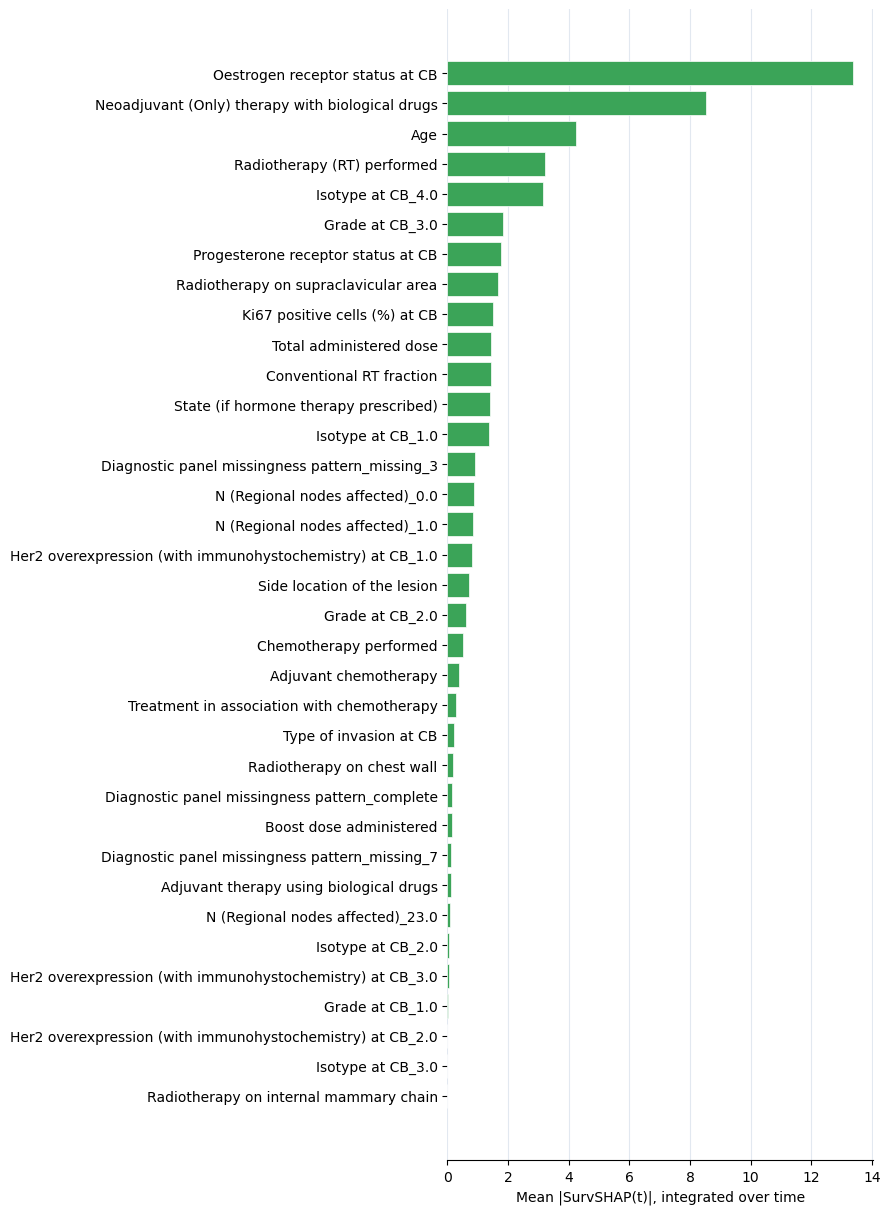

In [6]:
# --- RSF SurvSHAP global importance plot ---
# aggregated_change is a magnitude (mean |SurvSHAP(t)| integrated over the shared
# timestamp grid); it carries no sign or direction, so a single colour is used.
plot_df = rsf_survshap_importance.sort_values('aggregated_change', ascending=True).reset_index(drop=True)
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
ax.set_facecolor('none')
fig.patch.set_alpha(0.0)
ax.barh(y_pos, plot_df['aggregated_change'], color=plt.cm.Greens(0.65),
        edgecolor='white', linewidth=0.5, zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['variable_name'])
ax.set_xlabel('Mean |SurvSHAP(t)|, integrated over time')
ax.grid(axis='x', color='#E2E8F0', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('rsf_survshap_global_importance.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('rsf_survshap_global_importance.pdf', transparent=True, bbox_inches='tight')
plt.show()

In [ ]:
from sksurv.ensemble import GradientBoostingSurvivalAnalysis

# Collect predictions using repeated CV (same methodology as training)
predictions_df = collect_cv_predictions_for_calibration(
    model_class=RandomSurvivalForest,  
    X=x_train,
    y=y_train,
    model_params=rsf_params,
    time_points=time_points,
    scale_data=False,  # trees don't need scaling
    scaler_type='standard',
    random_state=None,
    n_jobs=-1,
    n_controls_per_case=None,  # No subsampling for calibration
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4,
    n_repeats=1,  # Use same CV setup as model training
    base_random_state=42,
    recalibrate=False,
    recalibration_type='beta',
    verbose=True
)

# Save predictions for later analysis
predictions_df.to_csv('rsf_calibration_predictions.csv', index=False)
print(f"\nPredictions saved to 'rsf_calibration_predictions.csv'")

# predictions_df = pd.read_csv("rsf_calibration_predictions.csv")

In [ ]:
# Generate calibration curves for all time points
fig, axes, calibration_results = plot_calibration_curves(
    predictions_df=predictions_df,
    time_points=time_points,
    n_bins=4,
    strategy='quantile',  # Equal-sized bins based on prediction quantiles
    figsize=(18, 6),
    save_path='rsf_calibration_curves.png',
    xlim=(0.9, 1),
    ylim=(0.9, 1),
    error_bar_type='se'
)

plt.show()

In [ ]:
# Basic usage
fig, axes, stats = plot_jittered_risk_scores(
    predictions_df=predictions_df,
    time_points=time_points,
    figsize=(18, 6),
    save_path='rsf_risk_score_distribution.png'
)

# Check separation statistics
for t, stat in stats.items():
    print(f"\nTime point {t} days:")
    print(f"  Events: {stat['n_events']}, No events: {stat['n_no_events']}")
    print(f"  Mean survival prob (event): {stat['event_mean']:.3f}")
    print(f"  Mean survival prob (no event): {stat['no_event_mean']:.3f}")
    print(f"  Cohen's d: {stat['cohens_d']:.2f}")